# Pass 20

## Problem Definition


Business problem: estimate a house’s sale price.

Data science problem: supervised regression, since we know the real prices and the target is a number.

## Data Collection/Sources


In [1]:
#import from IPython.display import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score
import statsmodels.api as sm
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from scipy import stats
from scipy import special

In [2]:
# file name
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

In [3]:
#load all the data
house_df= pd.read_csv(url)


In [4]:
# find all text columns (object)
obj_columns = house_df.select_dtypes(include=['object']).columns.tolist()
obj_columns

['MS Zoning',
 'Street',
 'Alley',
 'Lot Shape',
 'Land Contour',
 'Utilities',
 'Lot Config',
 'Land Slope',
 'Neighborhood',
 'Condition 1',
 'Condition 2',
 'Bldg Type',
 'House Style',
 'Roof Style',
 'Roof Matl',
 'Exterior 1st',
 'Exterior 2nd',
 'Mas Vnr Type',
 'Exter Qual',
 'Exter Cond',
 'Foundation',
 'Bsmt Qual',
 'Bsmt Cond',
 'Bsmt Exposure',
 'BsmtFin Type 1',
 'BsmtFin Type 2',
 'Heating',
 'Heating QC',
 'Central Air',
 'Electrical',
 'Kitchen Qual',
 'Functional',
 'Fireplace Qu',
 'Garage Type',
 'Garage Finish',
 'Garage Qual',
 'Garage Cond',
 'Paved Drive',
 'Pool QC',
 'Fence',
 'Misc Feature',
 'Sale Type',
 'Sale Condition']

In [5]:
# Keep ALL columns, but drop the ID columns (labels, not measurements)
house_df_all = house_df.drop(columns=['Order', 'PID'], errors='ignore').copy()

# list of number columns (includes SalePrice)
num_columns = house_df_all.select_dtypes(include=['int64', 'float64']).columns.tolist()
num_columns

['MS SubClass',
 'Lot Frontage',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'TotRms AbvGrd',
 'Fireplaces',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area',
 'Wood Deck SF',
 'Open Porch SF',
 'Enclosed Porch',
 '3Ssn Porch',
 'Screen Porch',
 'Pool Area',
 'Misc Val',
 'Mo Sold',
 'Yr Sold',
 'SalePrice']

In [6]:
# Columns data types
house_df_all.dtypes.sort_values()


,0
MS SubClass,int64
Low Qual Fin SF,int64
Gr Liv Area,int64
Full Bath,int64
Half Bath,int64
...,...
Condition 1,object
Kitchen Qual,object
Neighborhood,object
Land Slope,object


In [7]:
# look at first and last few rows
house_df_all.head()


,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,Inside,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


In [8]:
# look at the last few rows
house_df_all.tail()

,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,CulDSac,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


In [9]:
# look at shape and size

print(house_df_all.shape)
print(house_df_all.size)


(2637, 80)
210960


In [10]:
# display meta data (info)
house_df_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 80 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2637 non-null   int64  
 1   MS Zoning        2637 non-null   object 
 2   Lot Frontage     2188 non-null   float64
 3   Lot Area         2637 non-null   int64  
 4   Street           2637 non-null   object 
 5   Alley            180 non-null    object 
 6   Lot Shape        2637 non-null   object 
 7   Land Contour     2637 non-null   object 
 8   Utilities        2637 non-null   object 
 9   Lot Config       2637 non-null   object 
 10  Land Slope       2637 non-null   object 
 11  Neighborhood     2637 non-null   object 
 12  Condition 1      2637 non-null   object 
 13  Condition 2      2637 non-null   object 
 14  Bldg Type        2637 non-null   object 
 15  House Style      2637 non-null   object 
 16  Overall Qual     2637 non-null   int64  
 17  Overall Cond  

In [11]:
# summary statistics: numbers first, then text
display(house_df_all.describe())
display(house_df_all.describe(include='object'))



,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2637.000000,2188.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2614.000000,2636.000000,2636.000000,...,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000
mean,57.349261,69.166819,10044.694729,6.097459,5.569966,1971.288586,1984.202882,101.887911,438.441199,51.068665,...,94.305271,46.984452,22.813424,2.368601,15.775123,2.130072,42.014031,6.243838,2007.795601,179986.230186
std,42.499091,23.356779,6742.549521,1.411522,1.118262,30.306986,20.913077,179.578232,449.602326,172.521803,...,126.927272,66.564333,61.177638,23.160600,55.783751,35.140140,393.158781,2.722093,1.306403,78309.251522
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,20.000000,58.000000,7436.000000,5.000000,5.000000,1954.000000,1965.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,50.000000,68.000000,9450.000000,6.000000,5.000000,1973.000000,1993.000000,0.000000,368.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,70.000000,80.000000,11526.000000,7.000000,6.000000,2001.000000,2004.000000,164.000000,732.000000,0.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213000.000000
max,190.000000,313.000000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1526.000000,...,1424.000000,742.000000,584.000000,407.000000,576.000000,800.000000,12500.000000,12.000000,2010.000000,745000.000000


,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
count,2637,2637,180,2637,2637,2637,2637,2637,2637,2637,...,2492,2490,2490,2490,2637,11,528,96,2637,2637
unique,7,2,2,4,4,3,5,3,28,9,...,6,3,5,5,3,4,4,4,10,6
top,RL,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,Gd,MnPrv,Shed,WD,Normal
freq,2043,2625,111,1662,2365,2634,1924,2511,397,2273,...,1563,1106,2356,2400,2395,4,306,87,2286,2166


In [12]:
# look for how the often a value appears
house_df['SalePrice'].value_counts(dropna=False)


,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [13]:
# look for nulls in target and features
house_df_all.isnull().sum().sort_values(ascending=False)

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


## Data Cleaning


### Backup 1

In [14]:
# make backup
house_df_all_backup = house_df_all.copy()

In [15]:
# restore from backup
house_df_all = house_df_all_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [16]:
# look for nulls in feature in percentage
house_df_all.isnull().mean() * 100

,0
MS SubClass,0.000000
MS Zoning,0.000000
Lot Frontage,17.026925
Lot Area,0.000000
Street,0.000000
...,...
Mo Sold,0.000000
Yr Sold,0.000000
Sale Type,0.000000
Sale Condition,0.000000


### Impute

In [17]:
# 1. Number columns: fill with the median (same as Pass 13)
median_frontage = house_df_all['Lot Frontage'].median()
median_garage_yr = house_df_all['Garage Yr Blt'].median()
house_df_all['Lot Frontage'] = house_df_all['Lot Frontage'].fillna(median_frontage)
house_df_all['Garage Yr Blt'] = house_df_all['Garage Yr Blt'].fillna(median_garage_yr)

# 2. Number columns with only a few nulls: drop those rows (same as Pass 13)
house_df_all = house_df_all.dropna(subset=['Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2',
                                           'Bsmt Unf SF', 'Total Bsmt SF', 'Bsmt Full Bath',
                                           'Bsmt Half Bath', 'Garage Cars', 'Garage Area'])

# 3. Text columns: null means "doesn't have it", so fill with 'None'
house_df_all = house_df_all.fillna('None')

house_df_all.shape


(2611, 80)

In [18]:
#check that null are removed from object
house_df_all.isnull().sum()

,0
MS SubClass,0
MS Zoning,0
Lot Frontage,0
Lot Area,0
Street,0
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


## Exploratory Data Analysis


Linear Regression has two requirements:
1. the features are correlated with the target
1. the features are not correlated with each other

In [19]:
# How many categories does each column have?
house_df_all.nunique().sort_values()

,0
Street,2
Central Air,2
Land Slope,3
Alley,3
Bsmt Half Bath,3
...,...
Total Bsmt SF,994
1st Flr SF,1015
Bsmt Unf SF,1076
Gr Liv Area,1206


In [20]:
# Average price for each category in one feature
house_df_all.groupby('Neighborhood')['SalePrice'].mean().sort_values()

,SalePrice
Neighborhood,
MeadowV,96271.764706
IDOTRR,101245.915663
BrDale,106919.642857
OldTown,123955.233945
BrkSide,124995.052083
Edwards,126999.493976
SWISU,135271.659091
Landmrk,137000.000000
Sawyer,137046.123188


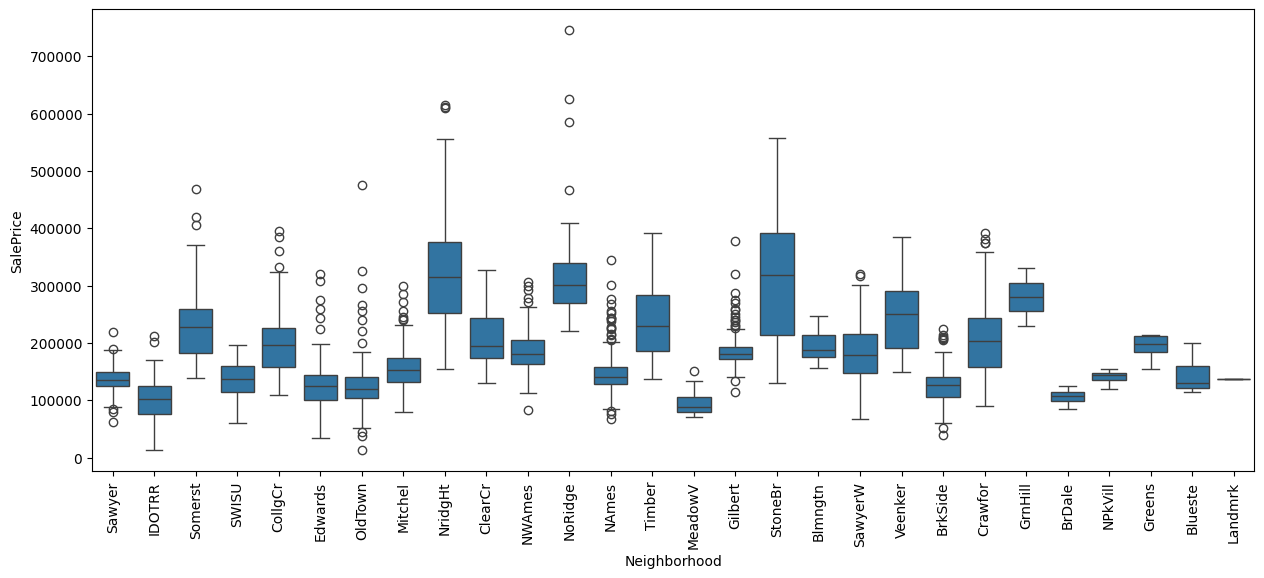

In [21]:
# Box plot: price spread for each category
# Boxes at very different heights = the feature is linked to price
# Boxes all at the same height = the feature doesn't tell you much
plt.figure(figsize=(15, 6))
sns.boxplot(data=house_df_all, x='Neighborhood', y='SalePrice')
plt.xticks(rotation=90)
plt.show()

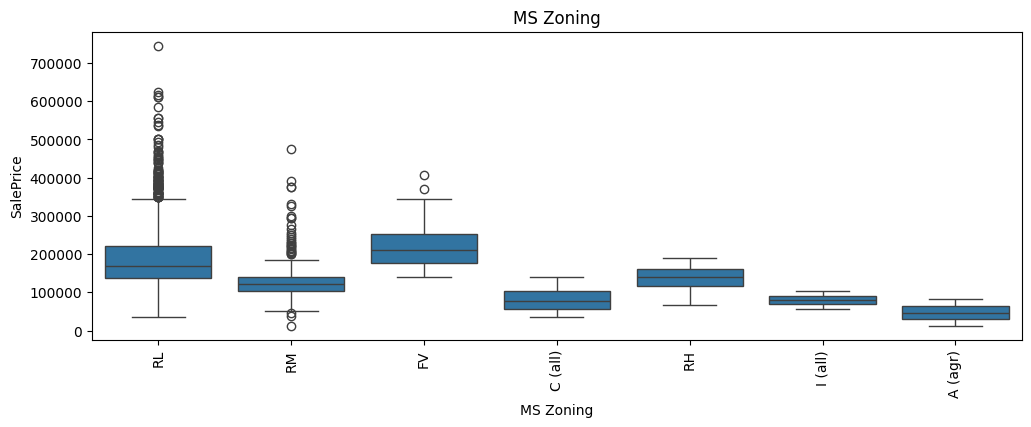

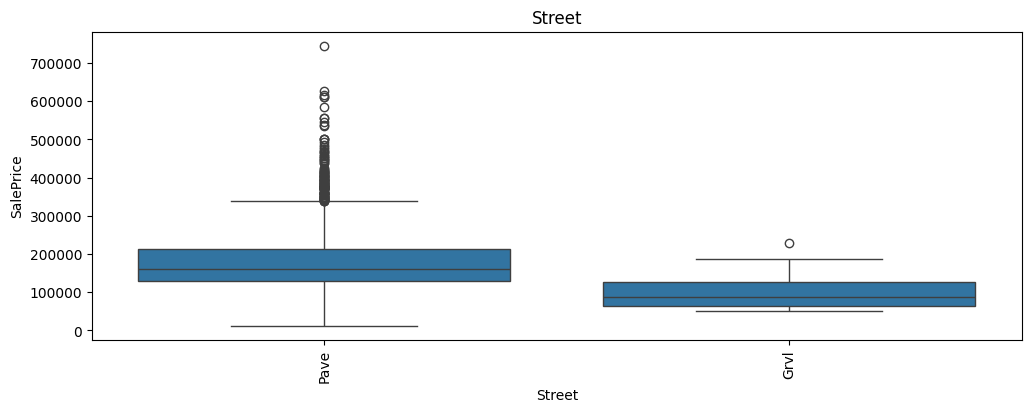

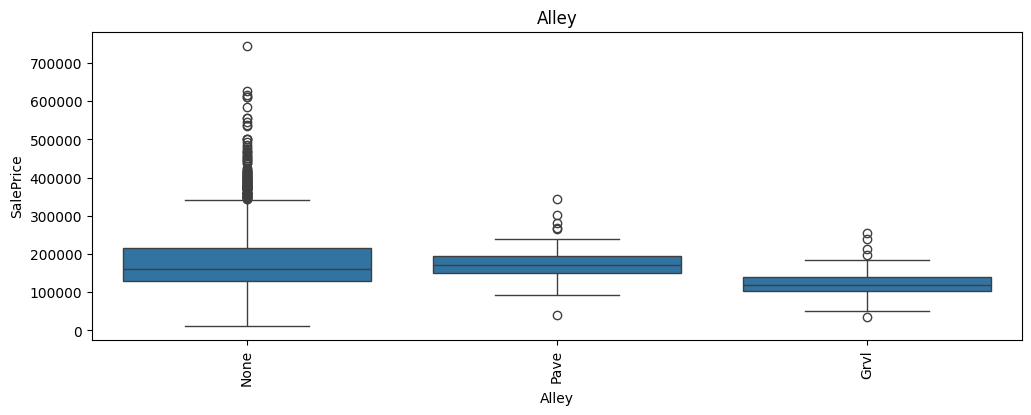

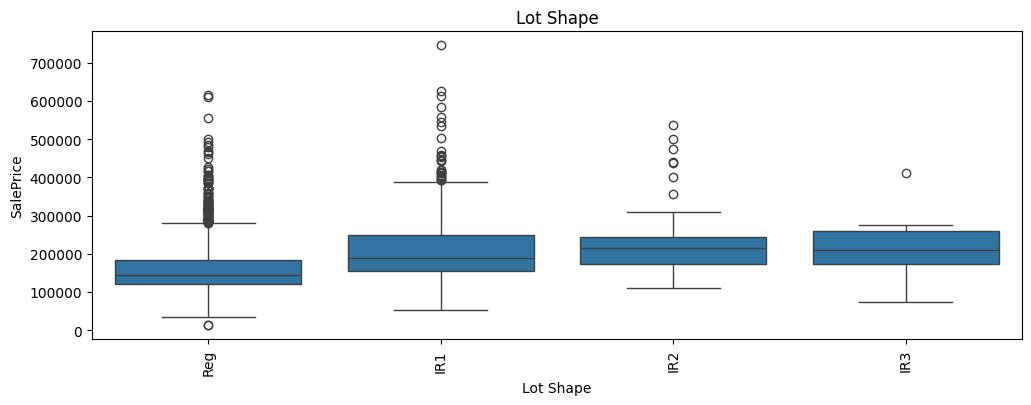

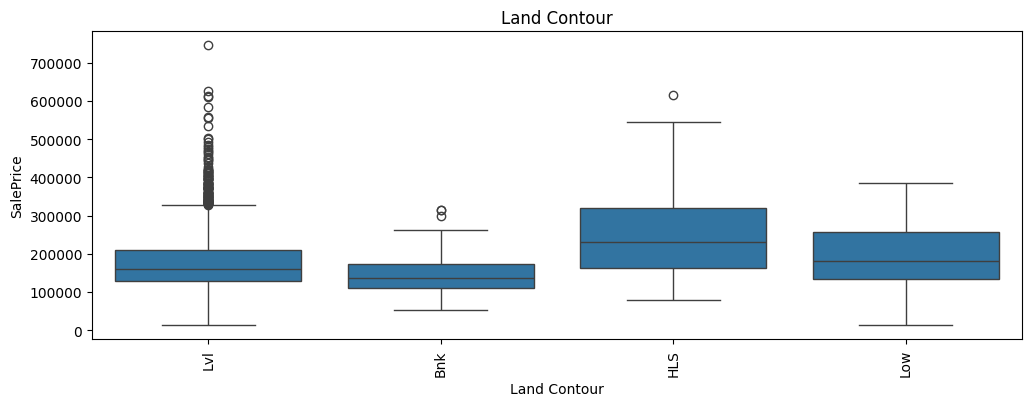

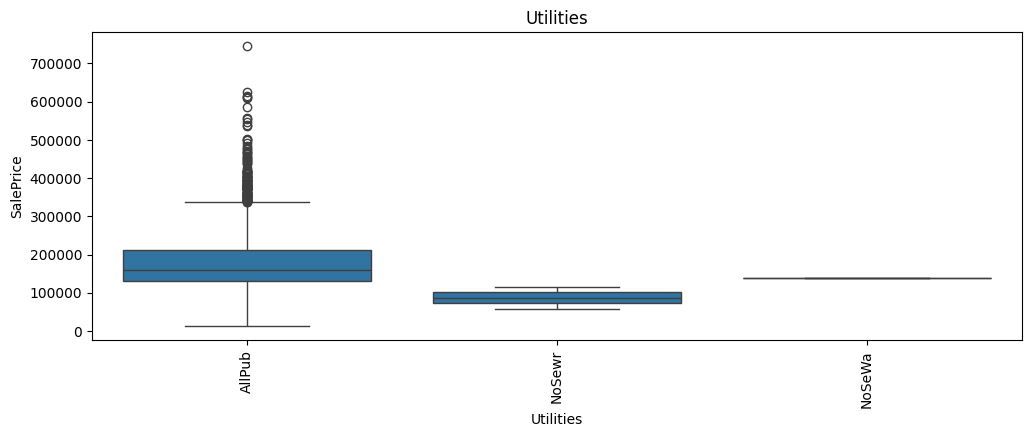

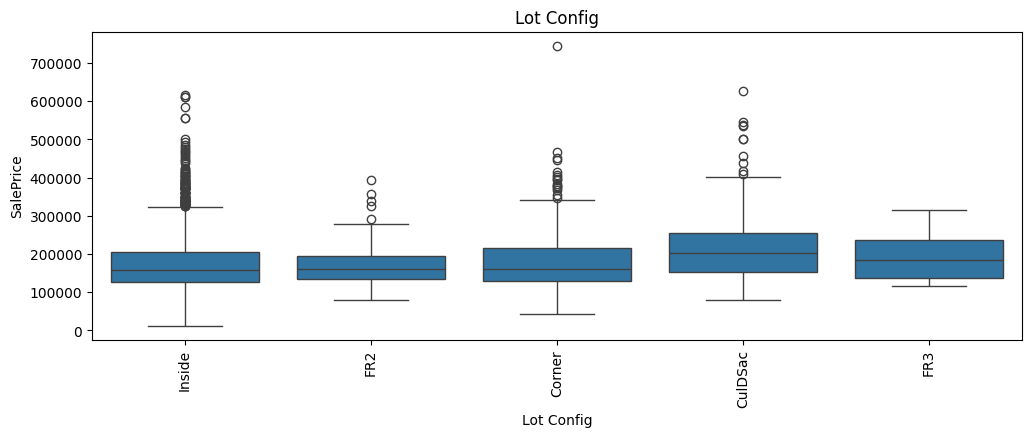

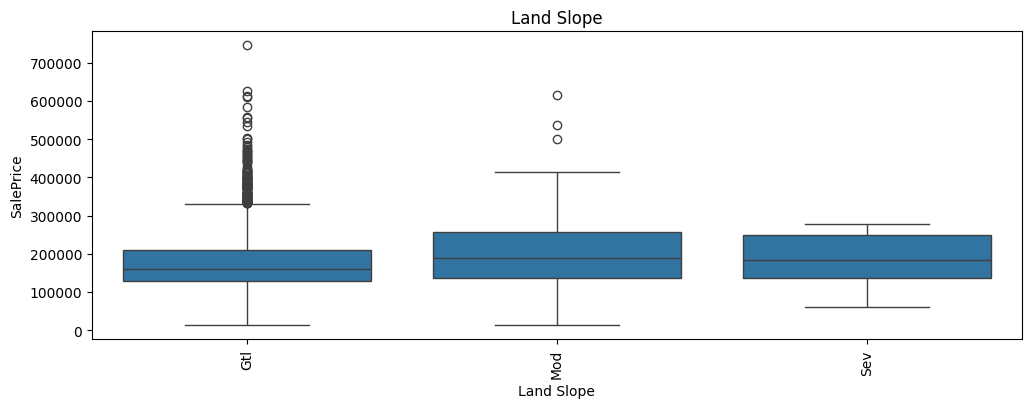

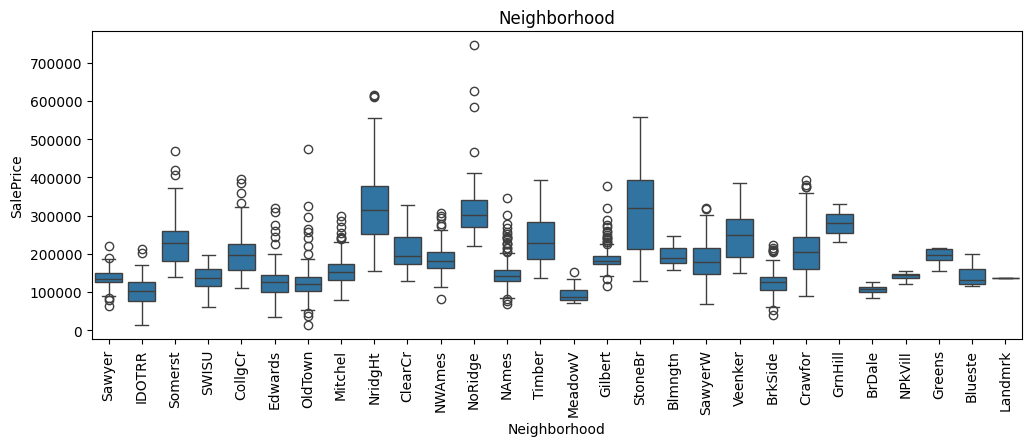

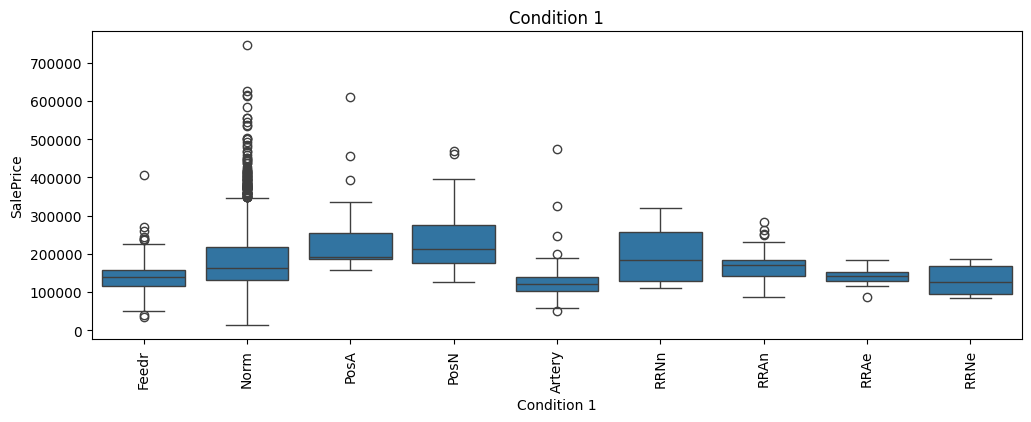

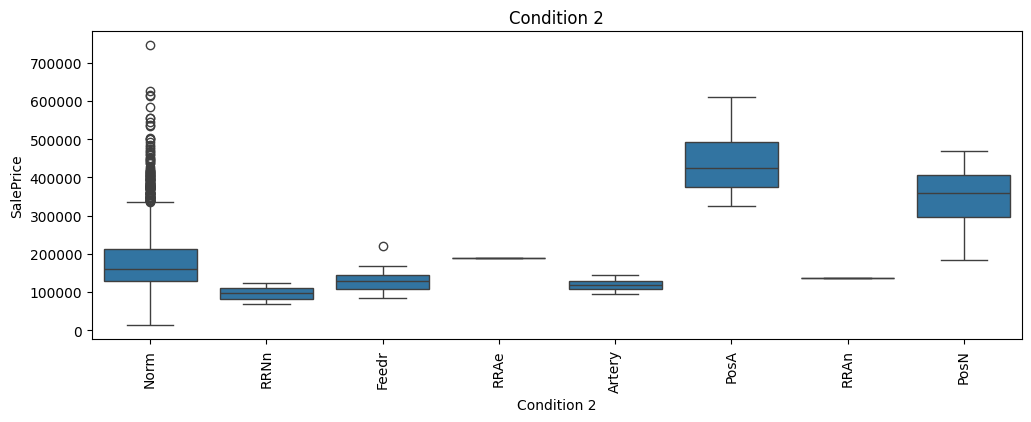

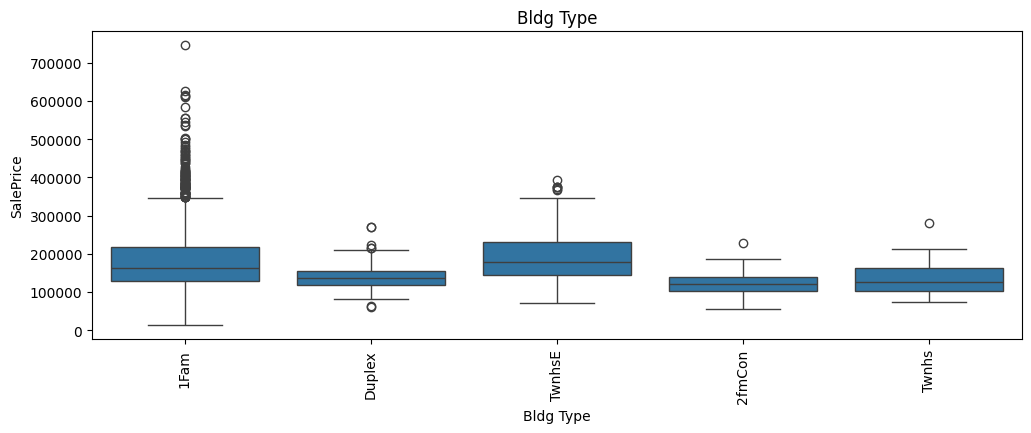

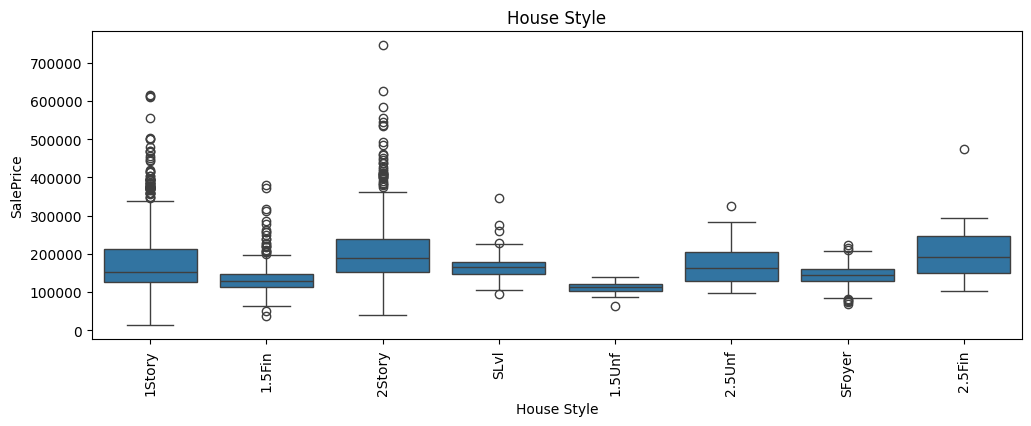

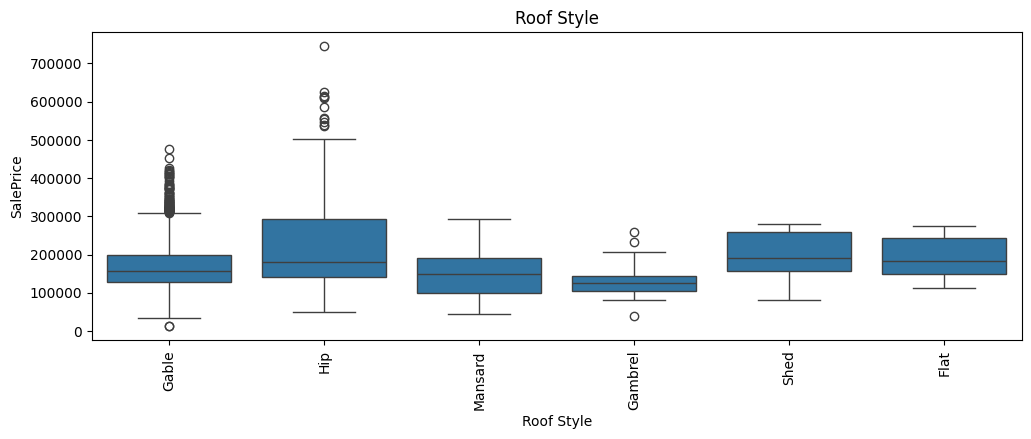

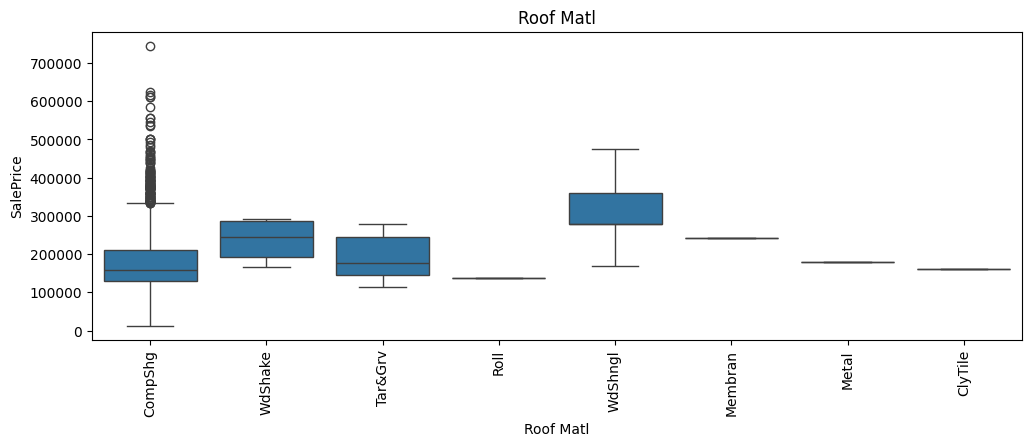

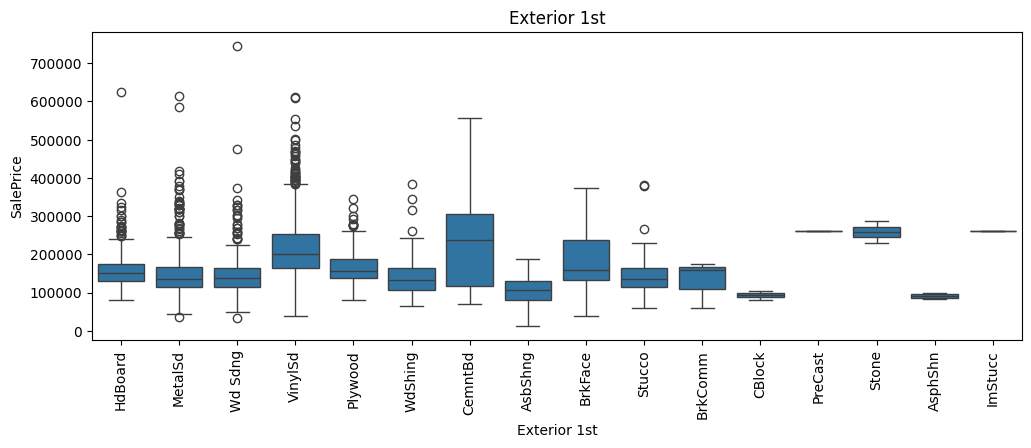

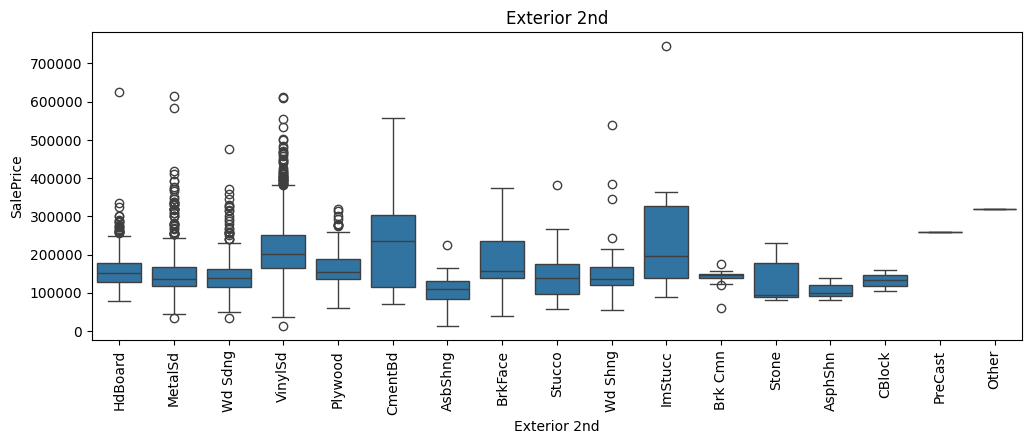

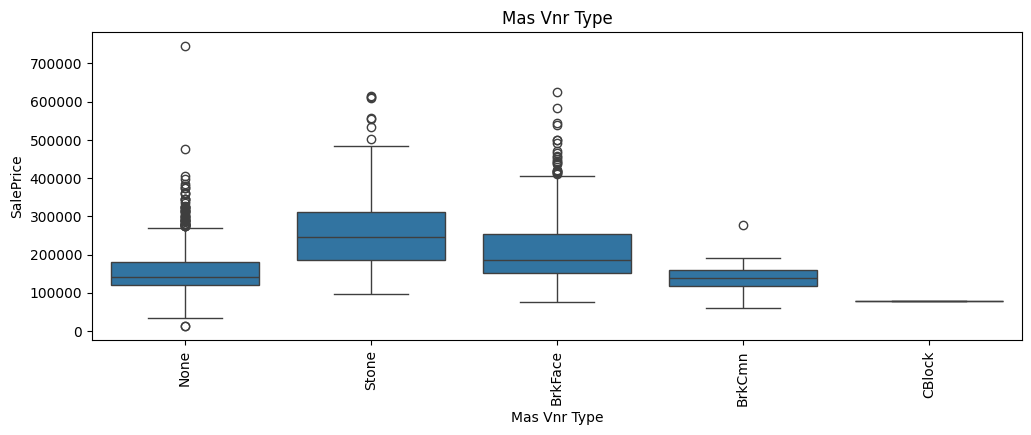

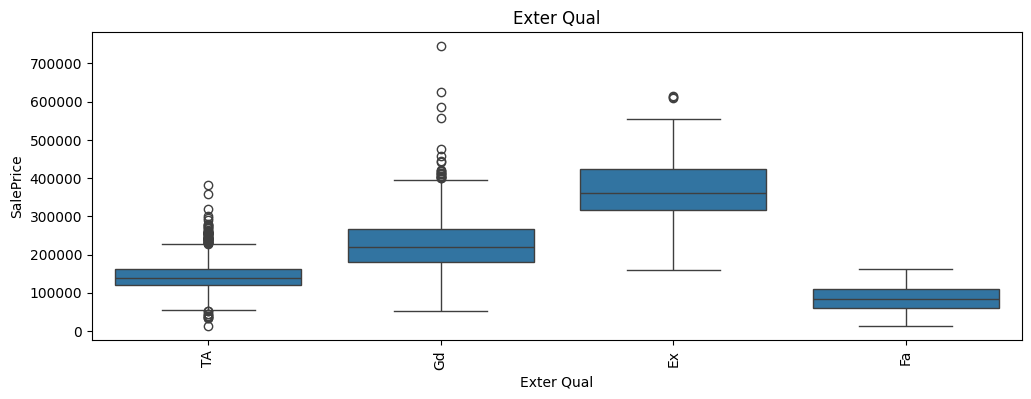

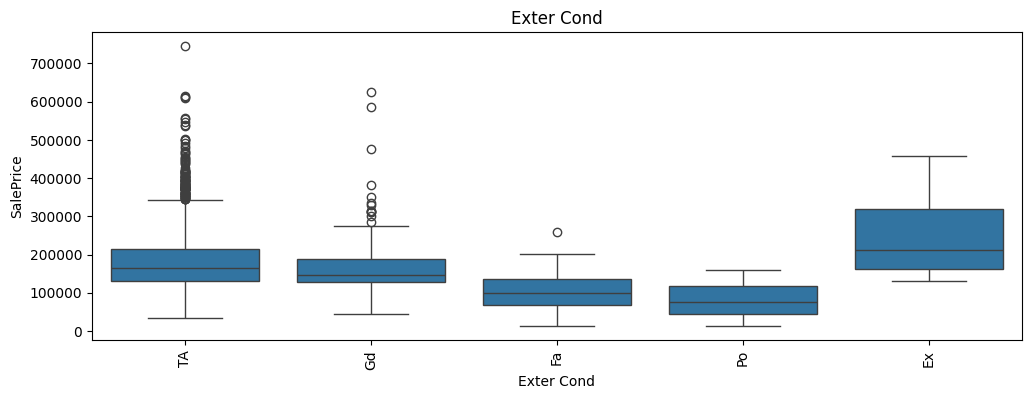

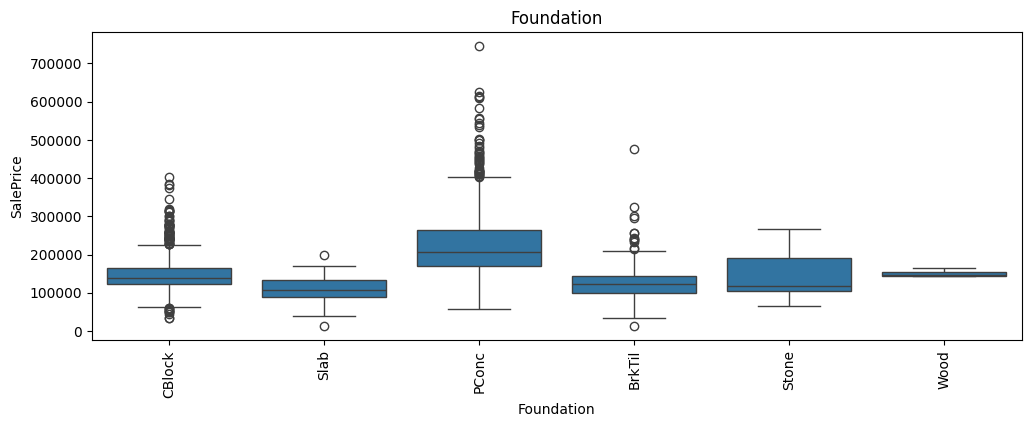

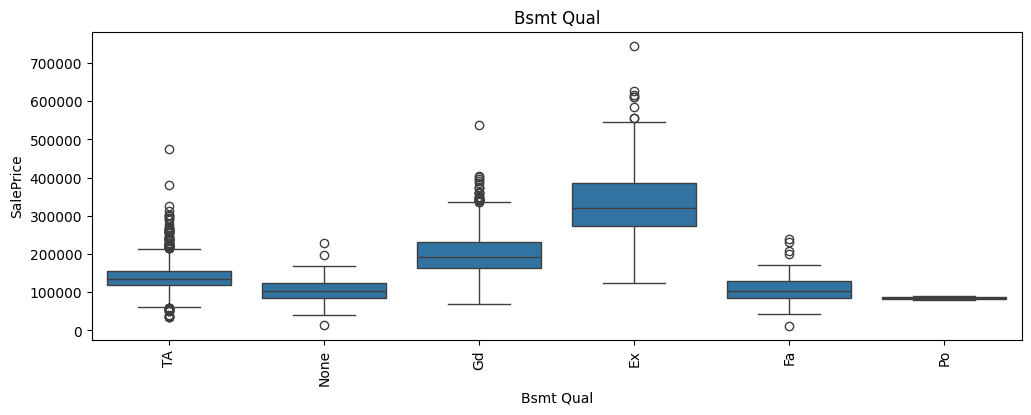

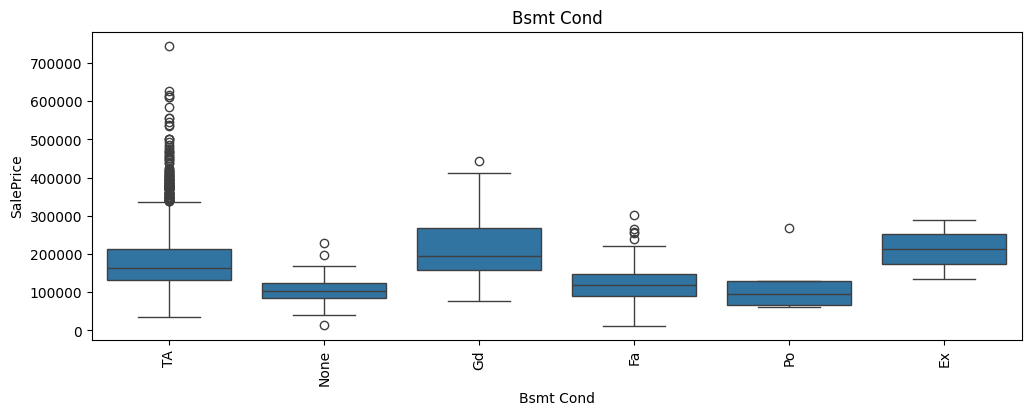

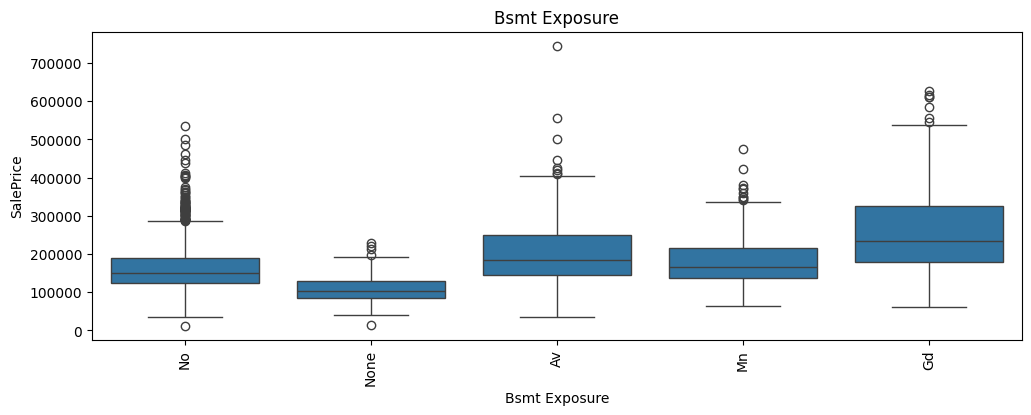

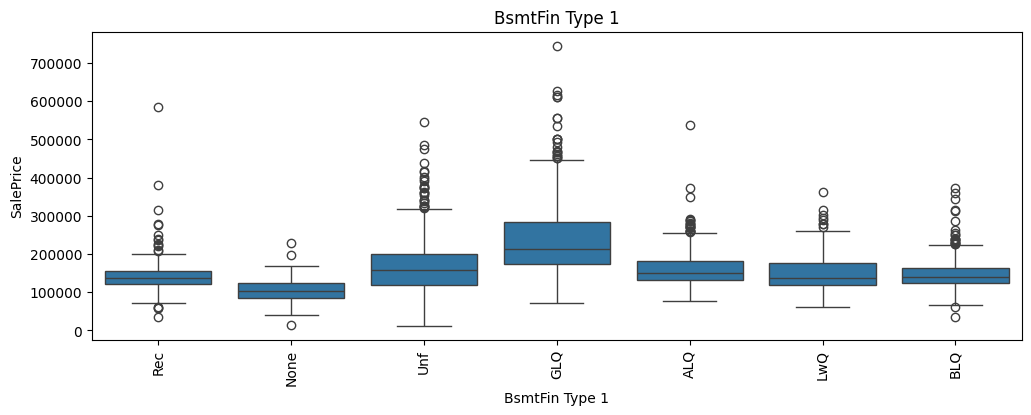

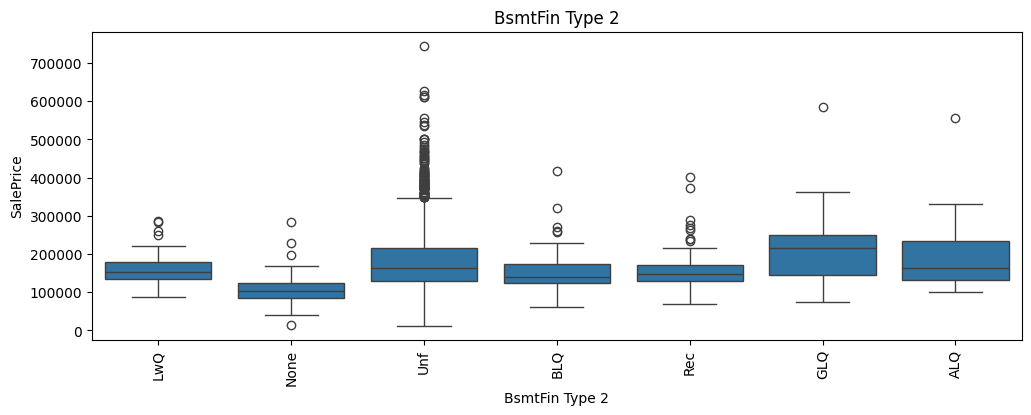

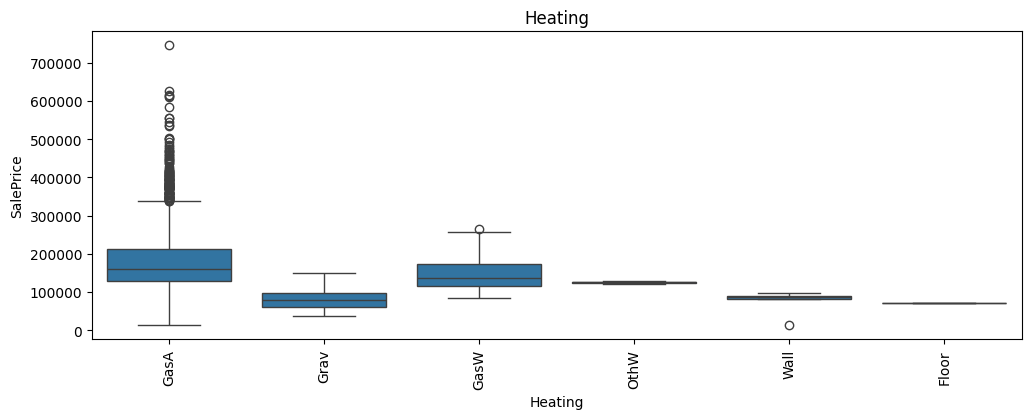

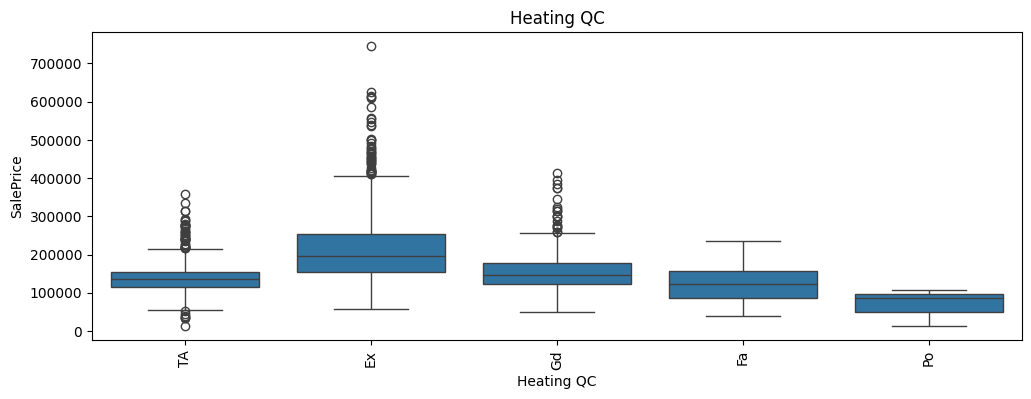

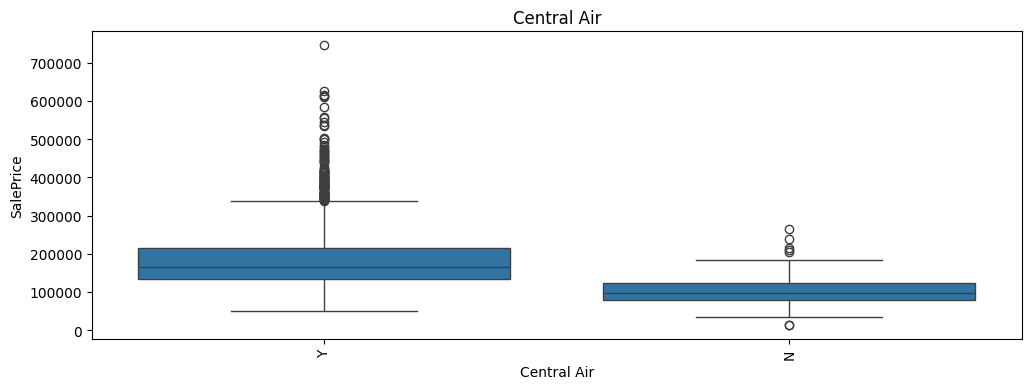

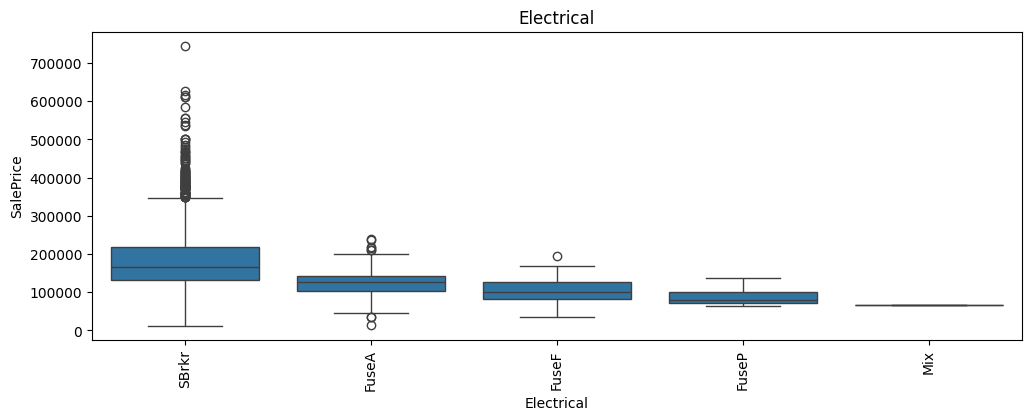

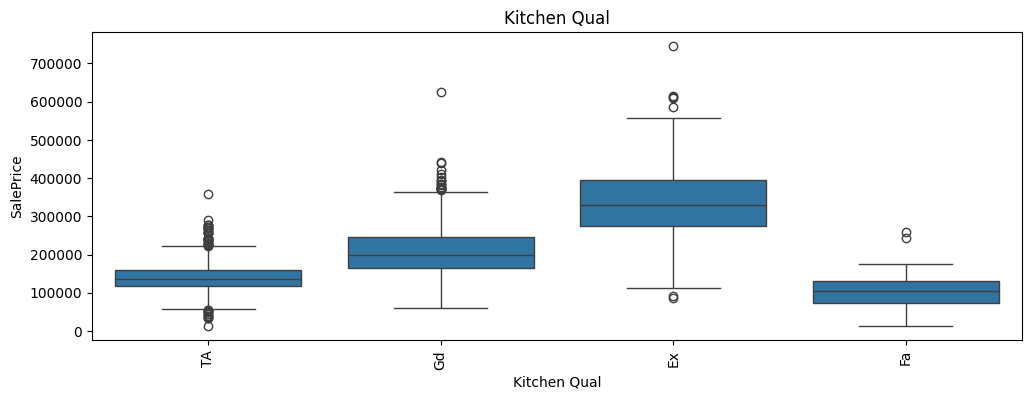

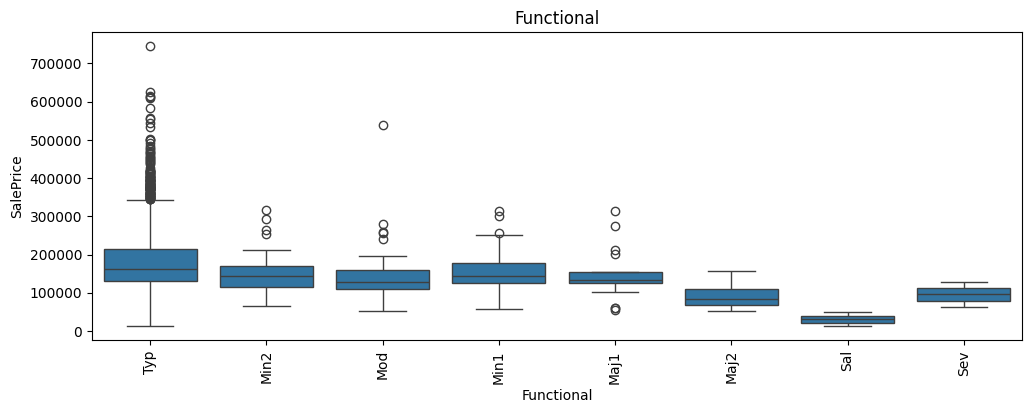

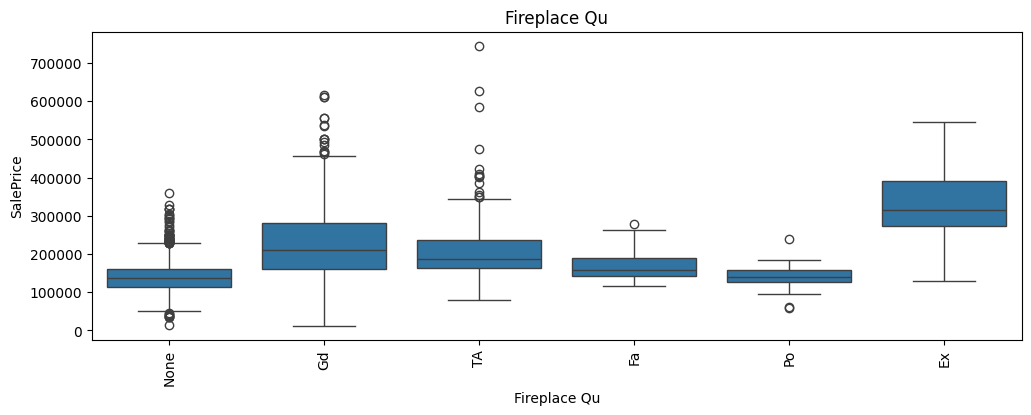

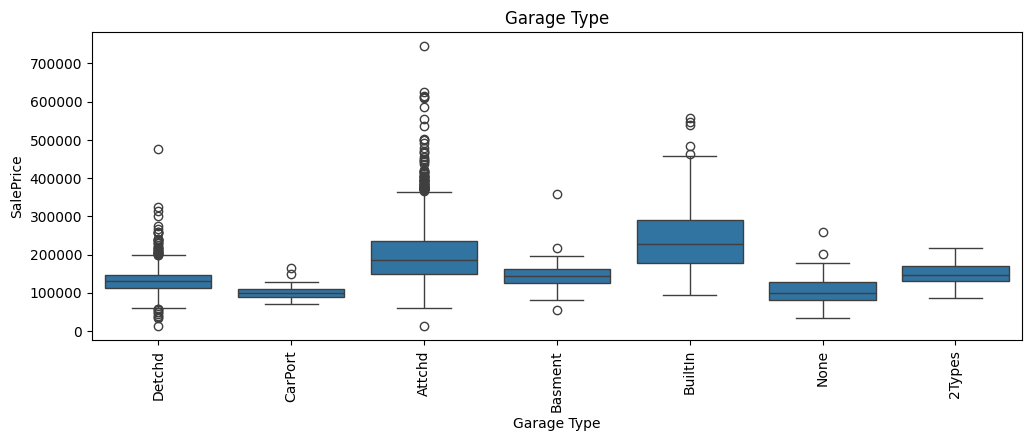

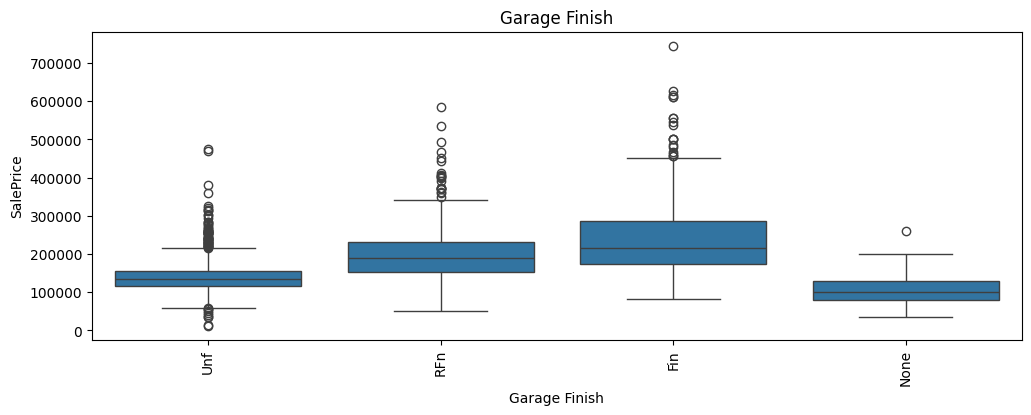

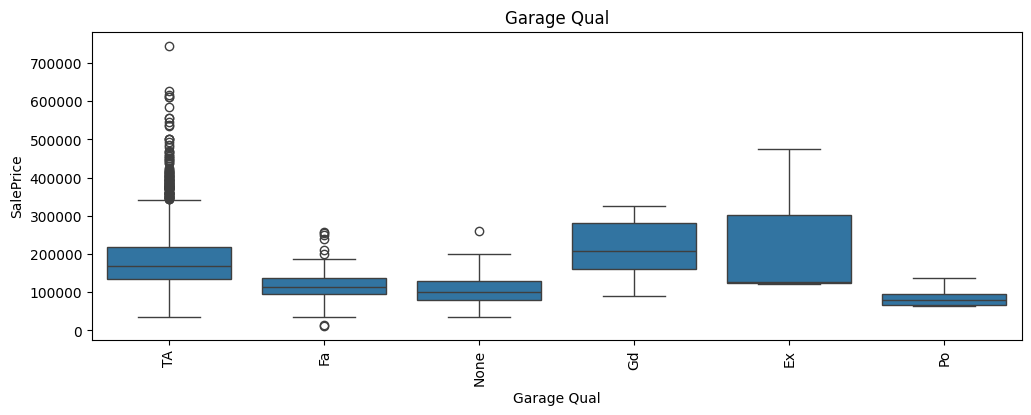

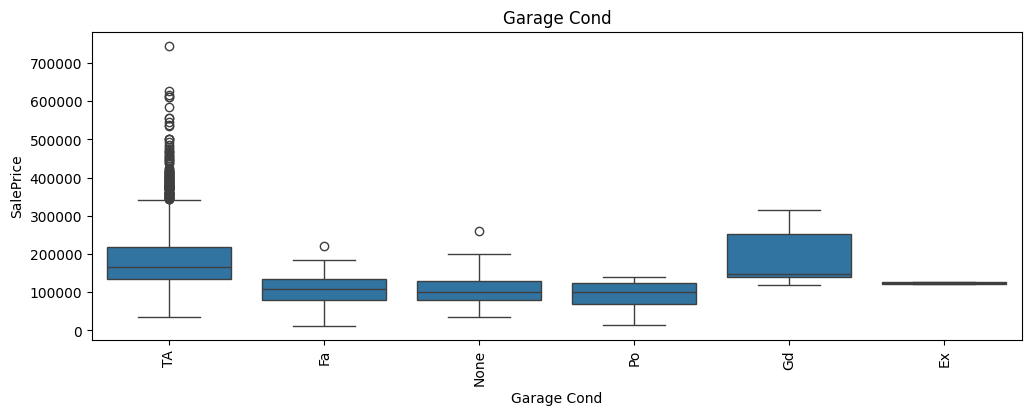

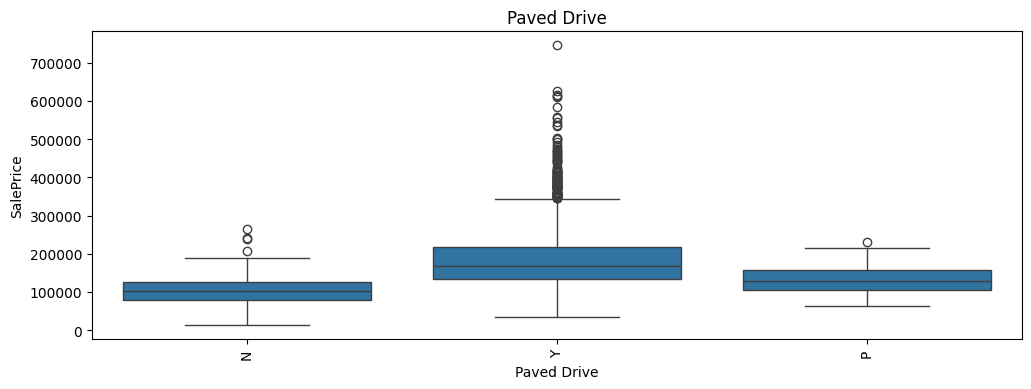

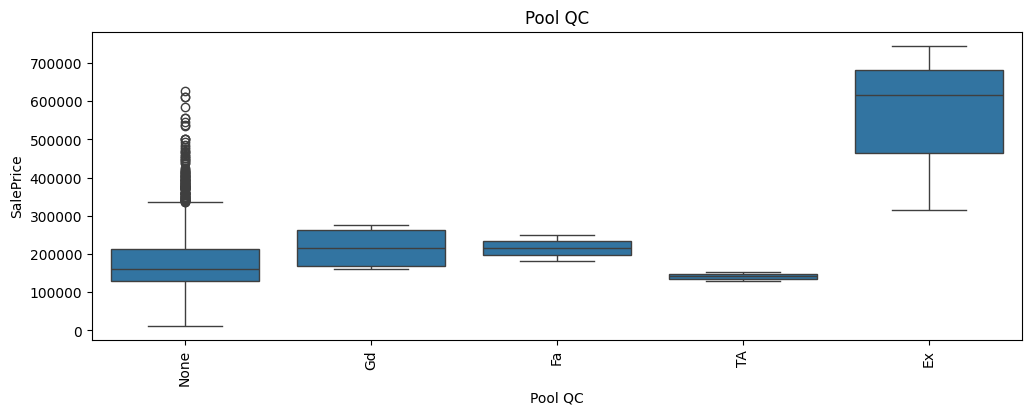

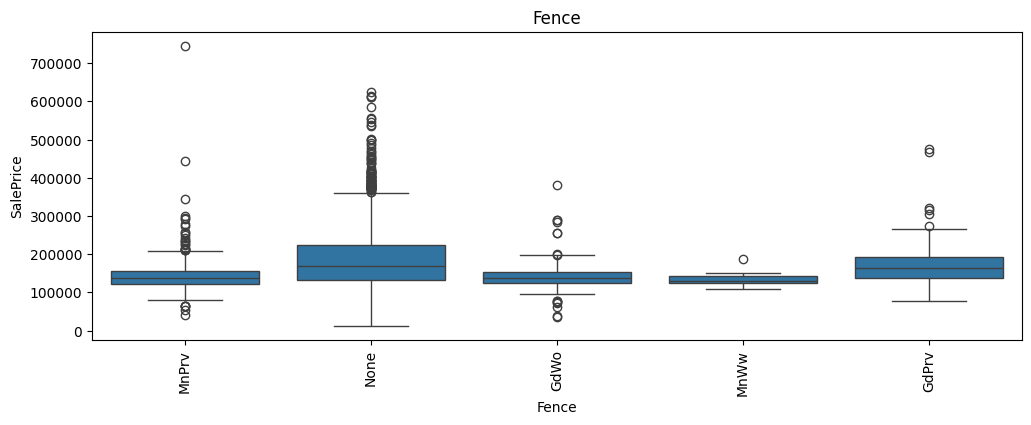

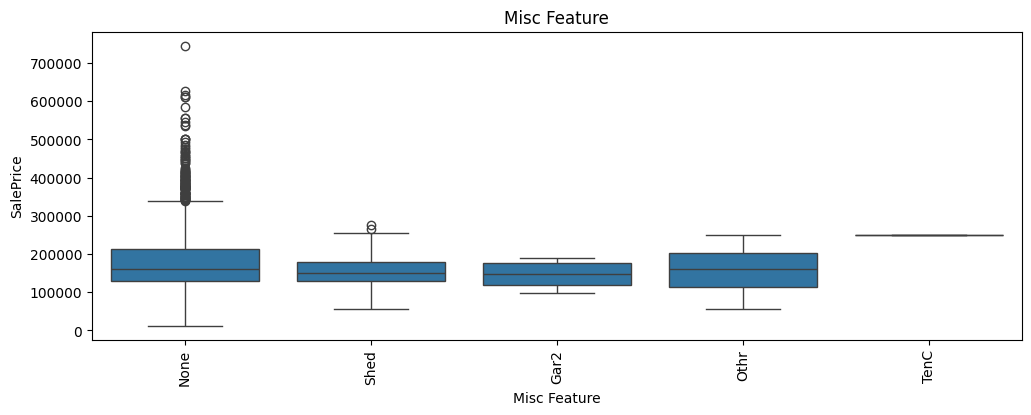

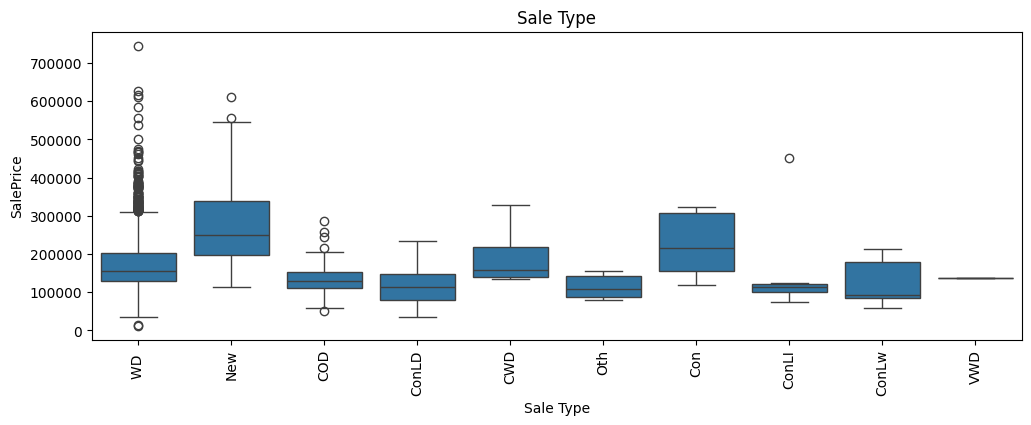

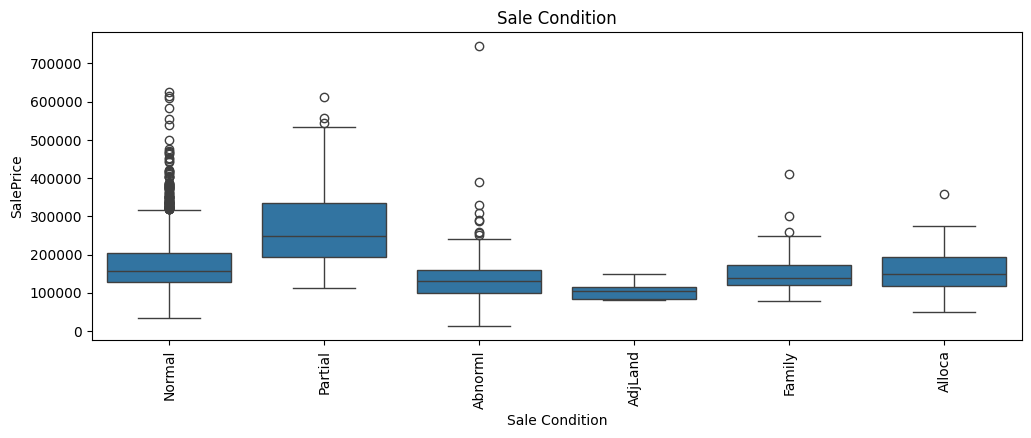

In [22]:
# Same box plot for every text feature
for col in obj_columns:
    plt.figure(figsize=(12, 4))
    sns.boxplot(data=house_df_all, x=col, y='SalePrice')
    plt.xticks(rotation=90)
    plt.title(col)
    plt.show()

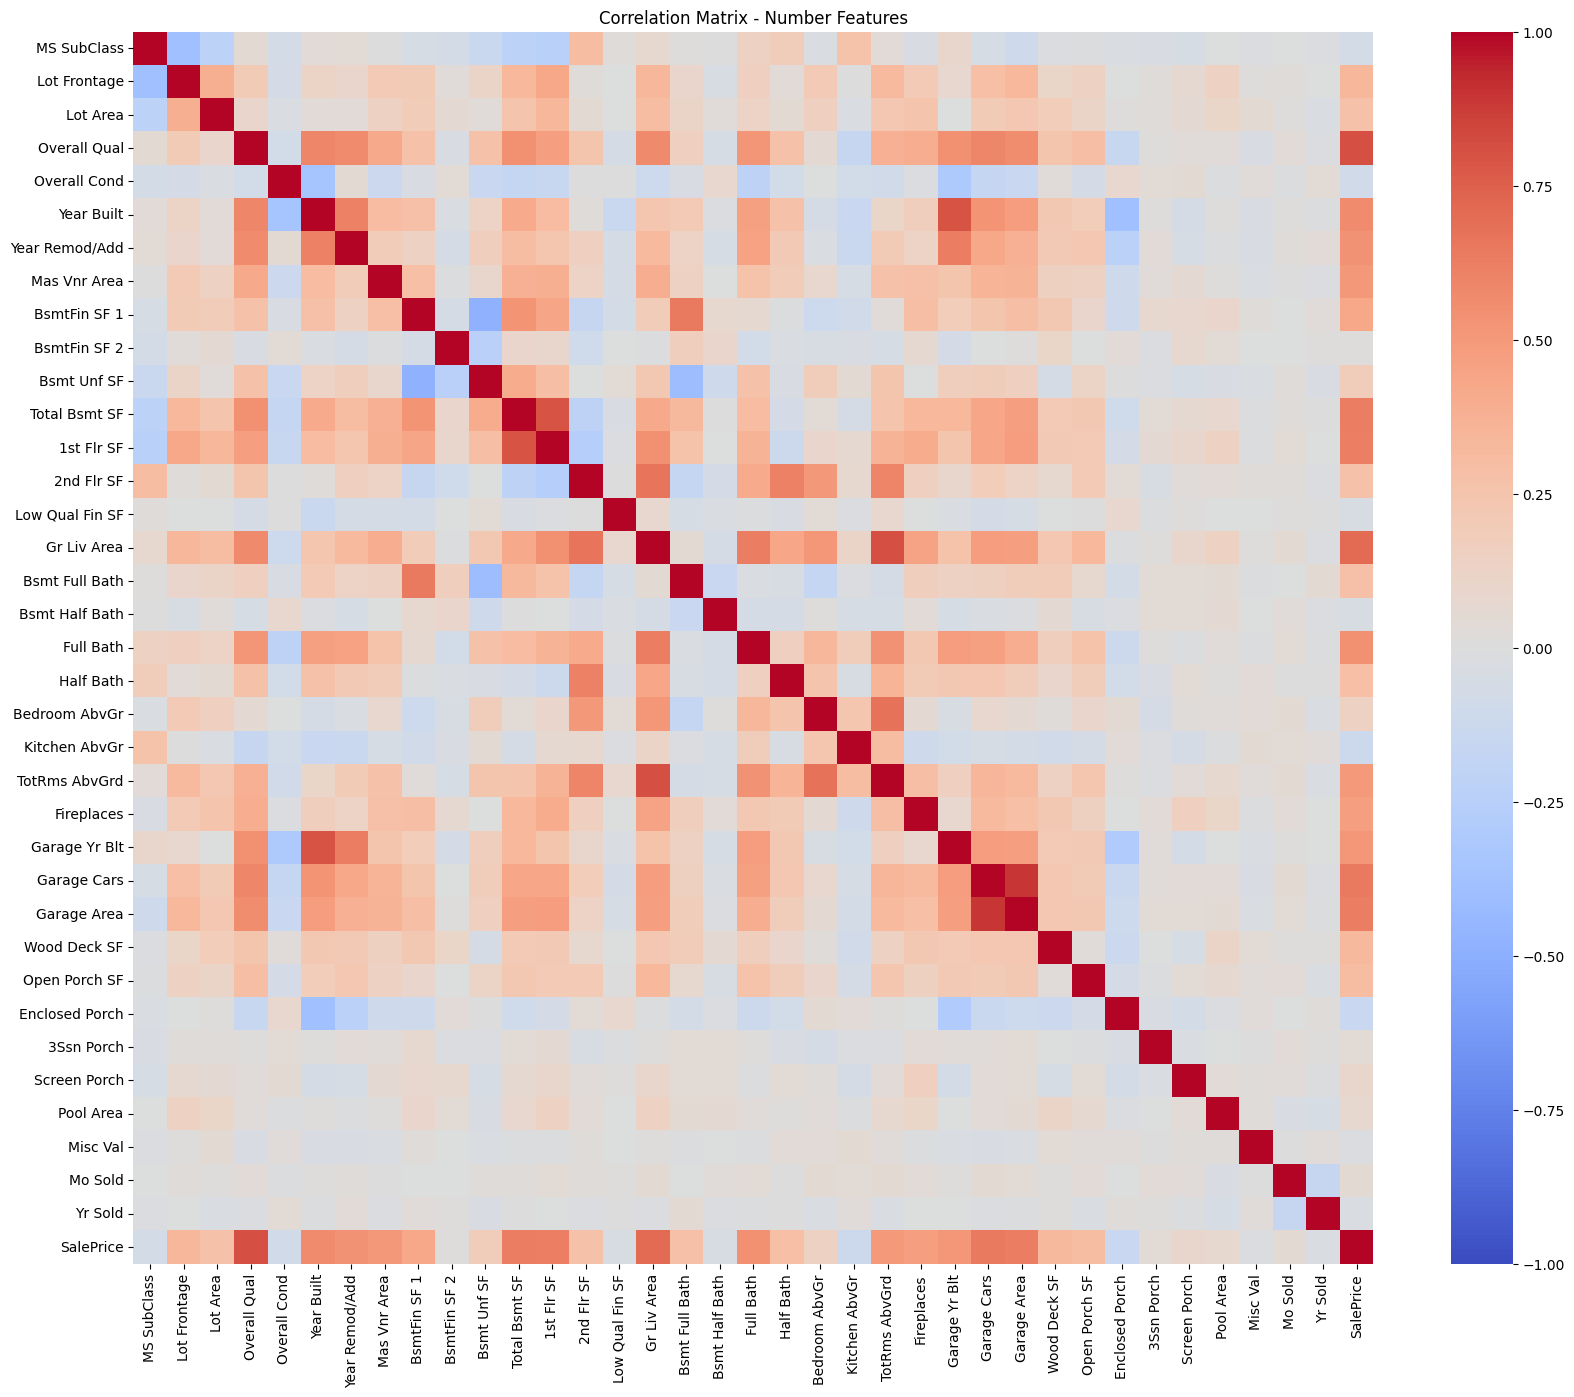

In [23]:
# Number features: correlation heatmap (text columns can't be in .corr())
plt.figure(figsize=(20, 16))
sns.heatmap(house_df_all[num_columns].corr(), annot=False,
            cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Correlation Matrix - Number Features')
plt.show()

Lambda: 0.03520881167313269


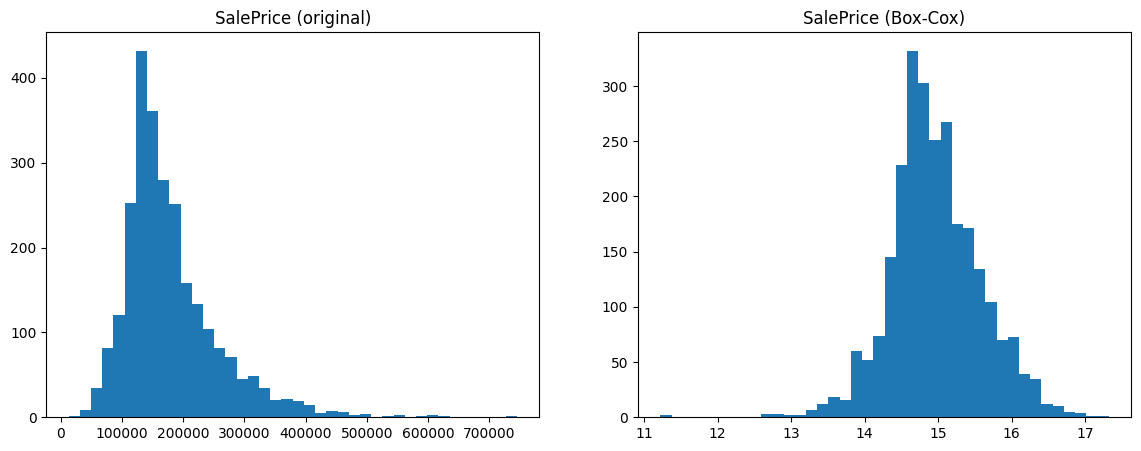

In [24]:
# Box-Cox: does it make SalePrice more bell-shaped?
fitted_data, fitted_lambda = stats.boxcox(house_df_all['SalePrice'])
print(f"Lambda: {fitted_lambda}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(house_df_all['SalePrice'], bins=40)
axes[0].set_title('SalePrice (original)')
axes[1].hist(fitted_data, bins=40)
axes[1].set_title('SalePrice (Box-Cox)')
plt.show()

#### Feature Selection

In [25]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression

In [26]:
# Target
y = house_df_all['SalePrice']

# Number features (drop the target)
X_num = house_df_all[num_columns].drop(columns=['SalePrice'])

# Text features, one-hot encoded
X_text = pd.get_dummies(house_df_all[obj_columns], drop_first=True, dtype=int)

# Everything together, for the starting score
X = pd.concat([X_num, X_text], axis=1)

print(X_num.shape, X_text.shape, X.shape)

(2611, 36) (2611, 237) (2611, 273)


In [27]:
# Find columns that are exact copies of another column
# Ridge splits credit evenly between twins, which would shrink both coefficients
dupes = X.columns[X.T.duplicated()].tolist()
print(dupes)

X = X.drop(columns=dupes)
X.shape

['Exterior 2nd_PreCast', 'Bsmt Cond_None', 'BsmtFin Type 1_None', 'Garage Qual_None', 'Garage Cond_None']


(2611, 268)

## Processing

### Fit & Assess model- Using Ridge Regression + Box-Cox

In [28]:
# Repeat CV - Ridge with ALL features (numbers + encoded text)
n = 500
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    model = Ridge(alpha=1)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    results[i] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Repeat CV RMSE (all features): {results.mean().round(2)}")
print(f"Number of features: {X.shape[1]}")

Repeat CV RMSE (all features): 32714.28
Number of features: 268


In [29]:
# Repeat CV - Ridge + Box-Cox with ALL features
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    fitted_data, fitted_lambda = stats.boxcox(y_train)          # Box-Cox the training prices
    model = Ridge(alpha=1)
    model.fit(X_train, fitted_data)                              # fit on Box-Cox prices
    real_y_pred = special.inv_boxcox(model.predict(X_test), fitted_lambda)   # back to dollars

    results[i] = np.sqrt(mean_squared_error(y_test, real_y_pred))

print(f"Repeat CV RMSE (Box-Cox, all features): {results.mean().round(2)}")
print(f"Number of features: {X.shape[1]}")

Repeat CV RMSE (Box-Cox, all features): 43130.81
Number of features: 268


In [30]:
# Fit Ridge once on Box-Cox prices to see each feature's coefficient
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
fitted_data, fitted_lambda = stats.boxcox(y_train)

model = Ridge(alpha=1)
model.fit(X_train_s, fitted_data)

coef_df = pd.DataFrame({'Feature': X.columns, 'Ridge': model.coef_})
coef_df['Abs'] = coef_df['Ridge'].abs()
coef_df.sort_values('Abs', ascending=False)

,Feature,Ridge,Abs
40,MS Zoning_RL,0.250850,0.250850
41,MS Zoning_RM,0.190089,0.190089
235,Garage Qual_TA,-0.188928,0.188928
15,Gr Liv Area,0.184115,0.184115
3,Overall Qual,0.170656,0.170656
...,...,...,...
17,Bsmt Half Bath,0.000017,0.000017
98,Condition 2_RRAe,0.000000,0.000000
261,Sale Type_VWD,0.000000,0.000000
99,Condition 2_RRAn,0.000000,0.000000


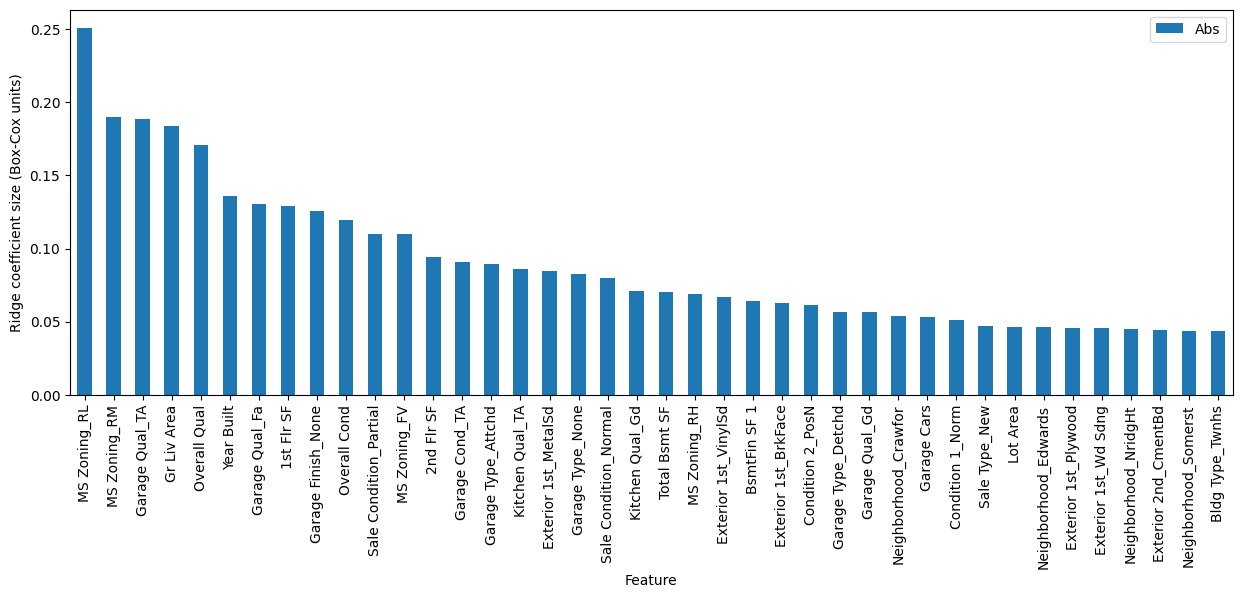

In [31]:
# Bar graph of the 40 biggest coefficients (now in Box-Cox units, so the numbers are small)
coef_df.sort_values('Abs', ascending=False).head(40).plot(x='Feature', y='Abs', kind='bar', figsize=(15,5))
plt.ylabel('Ridge coefficient size (Box-Cox units)');

In [32]:
# Cutoffs as a share of the biggest coefficient (0 = keep everything)
biggest = coef_df['Abs'].max()
cutoffs = [0, 0.01*biggest, 0.02*biggest, 0.05*biggest, 0.1*biggest, 0.2*biggest]
rows = []

for c in cutoffs:
    sel = coef_df[coef_df['Abs'] > c]['Feature'].tolist()
    X_c = X[sel]
    scores = np.zeros(100)
    for i in range(100):
        X_train, X_test, y_train, y_test = train_test_split(X_c, y, test_size=0.25)
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)
        fitted_data, fitted_lambda = stats.boxcox(y_train)
        model = Ridge(alpha=1)
        model.fit(X_train, fitted_data)
        real_y_pred = special.inv_boxcox(model.predict(X_test), fitted_lambda)
        scores[i] = np.sqrt(mean_squared_error(y_test, real_y_pred))
    rows.append({'Cutoff': c, 'Features': len(sel), 'RMSE': scores.mean()})

cutoff_df = pd.DataFrame(rows)
cutoff_df

,Cutoff,Features,RMSE
0,0.000000,264,48436.663982
1,0.002508,235,104049.541737
2,0.005017,206,56680.600605
3,0.012542,134,41964.995288
4,0.025085,82,33137.622333
5,0.050170,31,48862.673204


In [33]:
# Same rule as Pass 13: biggest cutoff whose RMSE is within 1% of the best
best_rmse = cutoff_df['RMSE'].min()
close_enough = cutoff_df[cutoff_df['RMSE'] <= best_rmse * 1.01]
best_cutoff = close_enough['Cutoff'].max()

selected = coef_df[coef_df['Abs'] > best_cutoff]['Feature'].tolist()
print(f"Cutoff: {best_cutoff}, features kept: {len(selected)}")
selected

Cutoff: 0.02508496665291615, features kept: 82


['MS SubClass',
 'Lot Area',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Total Bsmt SF',
 '1st Flr SF',
 '2nd Flr SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Full Bath',
 'Fireplaces',
 'Garage Cars',
 'Screen Porch',
 'MS Zoning_FV',
 'MS Zoning_RH',
 'MS Zoning_RL',
 'MS Zoning_RM',
 'Neighborhood_Crawfor',
 'Neighborhood_Edwards',
 'Neighborhood_GrnHill',
 'Neighborhood_MeadowV',
 'Neighborhood_NridgHt',
 'Neighborhood_OldTown',
 'Neighborhood_Somerst',
 'Neighborhood_StoneBr',
 'Condition 1_Norm',
 'Condition 2_PosN',
 'Bldg Type_Duplex',
 'Bldg Type_Twnhs',
 'House Style_1Story',
 'Roof Style_Gable',
 'Exterior 1st_BrkFace',
 'Exterior 1st_HdBoard',
 'Exterior 1st_MetalSd',
 'Exterior 1st_Plywood',
 'Exterior 1st_Stucco',
 'Exterior 1st_VinylSd',
 'Exterior 1st_Wd Sdng',
 'Exterior 2nd_CmentBd',
 'Mas Vnr Type_BrkFace',
 'Mas Vnr Type_None',
 'Mas Vnr Type_Stone',
 'Exter Qual_Gd',
 'Exter Qual_TA',
 'Exter Cond_Fa',
 'Foun

In [34]:
# Repeat CV - Ridge + Box-Cox with SELECTED features
X_sel = X[selected]
results = np.zeros(n)

for i in range(n):
    X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.25)
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)
    fitted_data, fitted_lambda = stats.boxcox(y_train)
    model = Ridge(alpha=1)
    model.fit(X_train, fitted_data)
    real_y_pred = special.inv_boxcox(model.predict(X_test), fitted_lambda)
    results[i] = np.sqrt(mean_squared_error(y_test, real_y_pred))

print(f"Repeat CV RMSE (Box-Cox, selected features): {results.mean().round(2)}")
print(f"Number of features: {len(selected)}")

Repeat CV RMSE (Box-Cox, selected features): 39651.21
Number of features: 82


In [35]:
# Final fit on selected features, fixed split, with Box-Cox
X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.2, random_state=4)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
fitted_data, fitted_lambda = stats.boxcox(y_train)

model = Ridge(alpha=1)
model.fit(X_train, fitted_data)

# Residual plots use y_pred, so make it the dollar predictions
y_pred = special.inv_boxcox(model.predict(X_test), fitted_lambda)

[(270000, np.float64(318409.0843129041)),
 (255000, np.float64(253331.78536533902)),
 (149900, np.float64(155495.21225390251)),
 (260000, np.float64(248056.61411111208)),
 (143750, np.float64(141432.27294713305)),
 (115000, np.float64(104309.23536979577)),
 (140000, np.float64(130157.12794188331)),
 (213750, np.float64(196270.83746895267)),
 (173000, np.float64(173067.0092384975)),
 (124500, np.float64(125548.12564318762))]

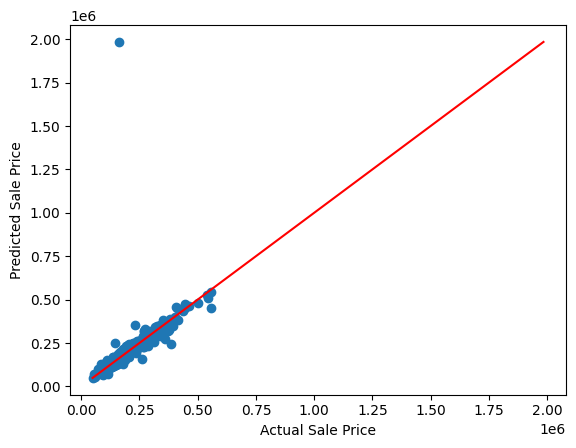

In [36]:
# See how well the model does compare to the test data
plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)], [min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price');

list(zip(y_test, y_pred))[:10]

In [37]:
# RMS on test data
rmse = mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse} ")

#RMSE- shows the amount the model was wrong

RMSE: 82400.45144686541 


## Residual Analysis

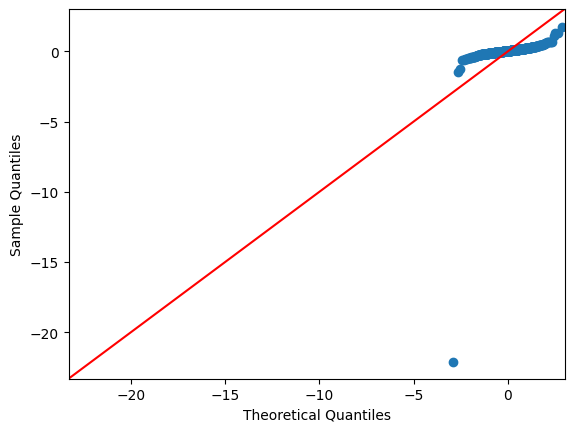

In [38]:
# QQ Plot - Checks if residuals(misses)are normally distributed (bell-shaped)
# res= real price- guess. Positive= guessed to low. Negative= guesses to high
# fit=True, converts model misses from dollars into standard units
# line="45" draws a line where "should be" = "actually is
# Read it: dots on red line= normal. Ends curving away= not normal


res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

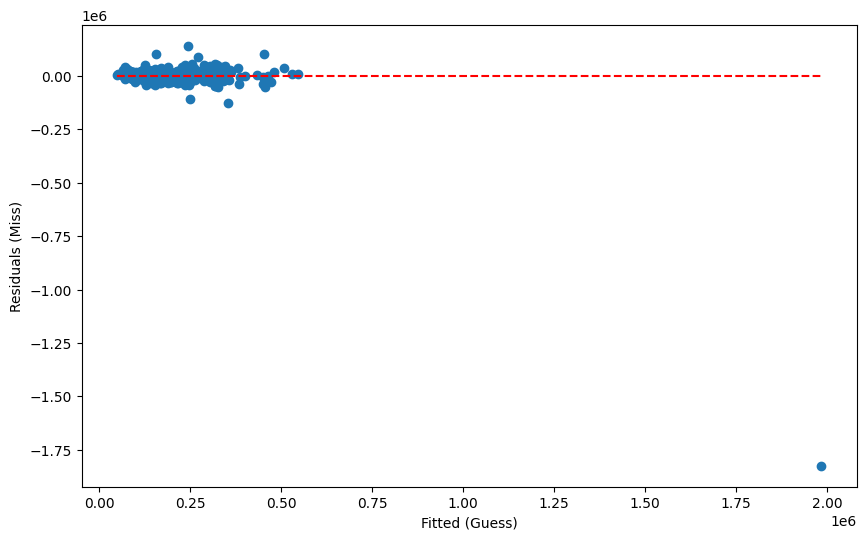

In [39]:
# Residuals vs Fitted (Predicted) Values - Constant variance

plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted (Guess)")
plt.ylabel("Residuals (Miss)")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

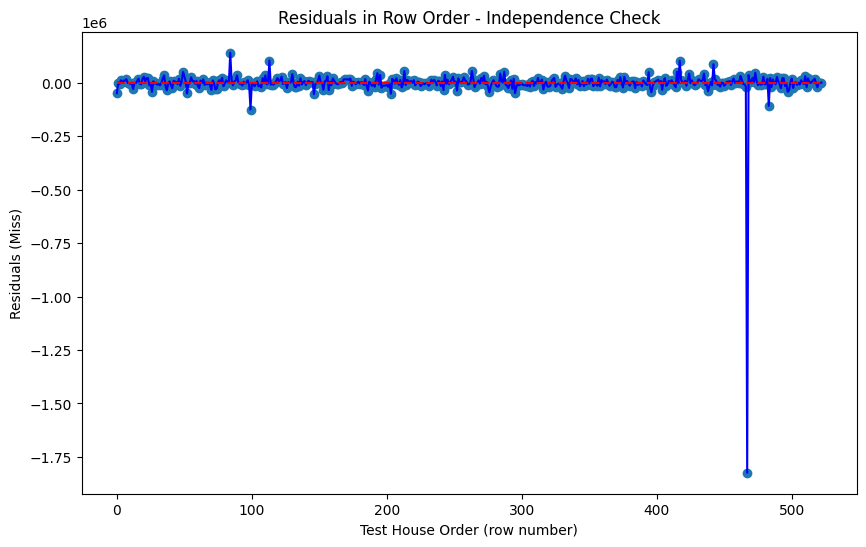

In [40]:
# Residuals vs Time - checks independence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Test House Order (row number)")
plt.ylabel("Residuals (Miss)")
plt.title("Residuals in Row Order - Independence Check")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;